# UTH Computer Vision Coursework — Topic 11
## Notebook 02: Stable Diffusion Generation & Automated Curation Gate
- **Nhóm thực hiện**: Nhóm 4
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Mục tiêu**: Trực quan hóa các chế độ sinh ảnh giả bằng Stable Diffusion (`sd_text2img`, `sd_inpaint`, `sd_img2img`) và kiểm chứng bộ lọc chất lượng tự động `ImageCurationGate`.

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch

from src.common.config import load_config
from src.common.metrics import compute_laplacian_sharpness
from src.pipelines.curate_image_dataset import ImageCurationGate

print('Environment initialized successfully.')
print(f'Project Root: {Path.cwd()}')


Environment initialized successfully.
Project Root: /home/bush/Projects/uth-cv-coursework


### 1. Nạp danh mục ảnh giả đã sinh (`paths.curated_manifest`)

In [2]:
cfg = load_config(Path('configs/dataset_factory.yaml'))
curated_manifest = Path(cfg['paths']['curated_manifest'])
curated_items = []
if curated_manifest.exists():
    with open(curated_manifest, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                curated_items.append(json.loads(line))

print(f'Số lượng ảnh giả đạt chuẩn Curation Gate: {len(curated_items)}')


Số lượng ảnh giả đạt chuẩn Curation Gate: 2200


### 2. Kiểm định độ sắc nét Laplacian qua Curation Gate

Độ sắc nét Laplacian trung bình: 7.91
Giá trị nhỏ nhất / lớn nhất: 3.03 / 27.77


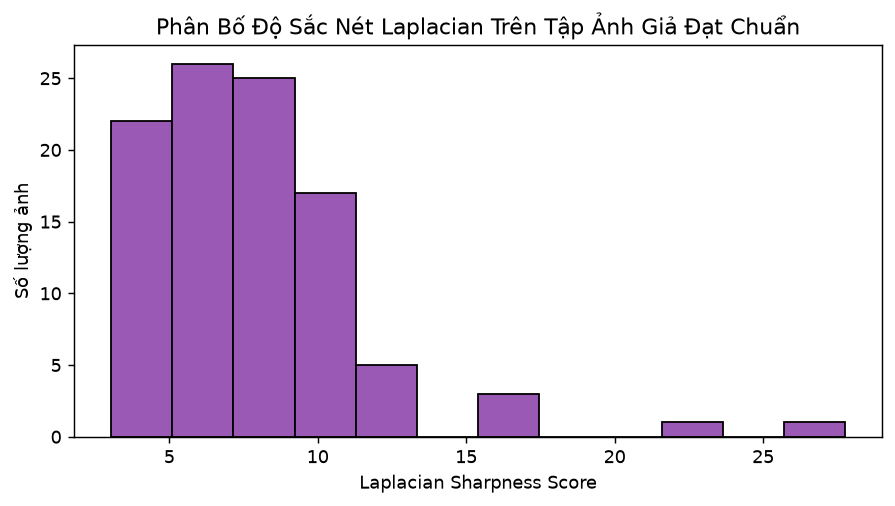

In [3]:
sharpness_scores = []
for item in curated_items[:100]:
    fp = item.get('file_path')
    if fp and Path(fp).exists():
        with Image.open(fp) as im:
            np_arr = np.array(im.convert('RGB'), dtype=np.float32) / 255.0
            t = torch.from_numpy(np_arr).permute(2, 0, 1)
            score = compute_laplacian_sharpness(t)
            sharpness_scores.append(score)

if sharpness_scores:
    print(f'Độ sắc nét Laplacian trung bình: {np.mean(sharpness_scores):.2f}')
    print(f'Giá trị nhỏ nhất / lớn nhất: {np.min(sharpness_scores):.2f} / {np.max(sharpness_scores):.2f}')
    plt.figure(figsize=(7, 4))
    plt.hist(sharpness_scores, bins=12, color='#9b59b6', edgecolor='black')
    plt.title('Phân Bố Độ Sắc Nét Laplacian Trên Tập Ảnh Giả')
    plt.xlabel('Sharpness Score')
    plt.ylabel('Số lượng ảnh')
    plt.tight_layout()
    plt.show()


### 3. Trực quan hóa ảnh khuôn mặt giả sinh bởi Stable Diffusion

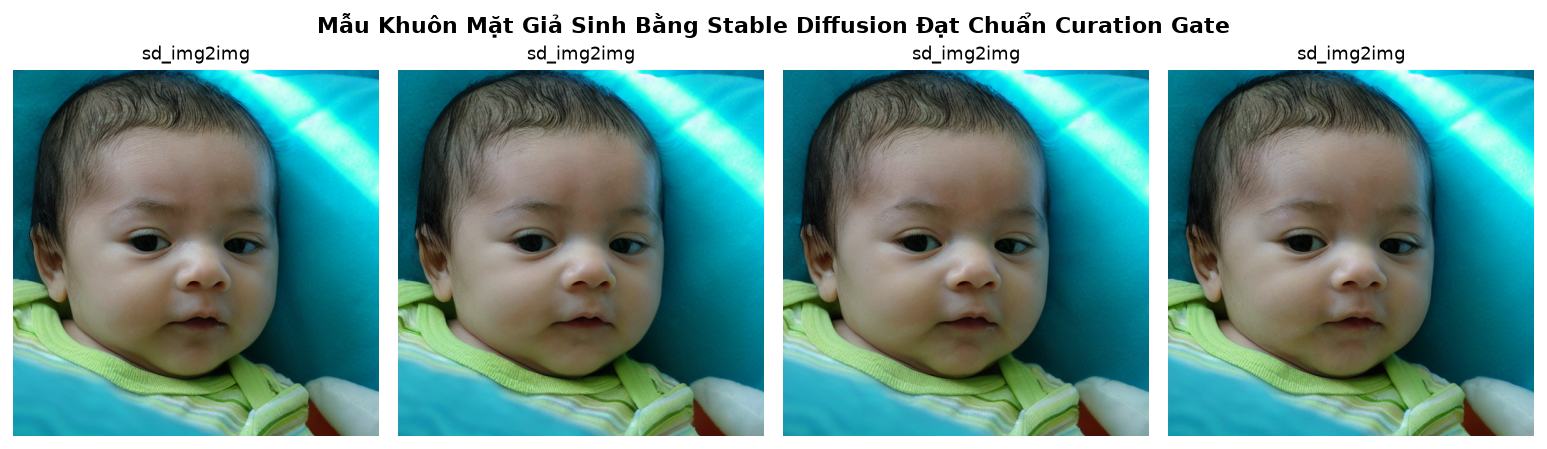

In [4]:
n = min(4, len(curated_items))
if n > 0:
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
    if n == 1:
        axes = [axes]
    for idx in range(n):
        item = curated_items[idx]
        fp = item.get('file_path')
        if fp and Path(fp).exists():
            im = Image.open(fp)
            axes[idx].imshow(im)
        axes[idx].set_title(item.get('manipulation_type', 'fake'), fontsize=10)
        axes[idx].axis('off')
    plt.suptitle('Mẫu Khuôn Mặt Giả Sinh Bằng Stable Diffusion Đạt Chuẩn Curation Gate', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
